# Phase 13A: Dataset Separability & Label-Consistency Audit

## 1. Objective & Audit Framework
Before attempting further model experimentation or architecture scaling to improve classification performance beyond **Model F (Ratio-Focused LightGBM)**, we must answer a fundamental data-centric question:
> *Can the current resume–job dataset realistically support substantially higher classification performance (e.g., 70–80% 3-class accuracy), or is performance constrained by intrinsic label ambiguity, structural overlap, and annotation inconsistency?*

### Audit Target Classes:
- `No Fit`
- `Potential Fit`
- `Good Fit`

### Locked Engineering Constraints:
1. Production classifier (**Model F**) is locked and untouched.
2. Production inference pipeline and 18 features are locked and untouched.
3. Candidate train/val/test split and official test benchmark are locked.
4. Read-only diagnostic audit: No models are retrained, no datasets altered, no code modified.


In [1]:
import os
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import entropy
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score, roc_curve

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Diagnostic audit environment initialized.")


Diagnostic audit environment initialized.


## 2. Dataset Verification & Split Architecture
We inspect the exact files used across the benchmark:
- `data/raw/train.csv` (Raw training pool, $N=6,241$)
- `data/raw/test.csv` (Official unseen-job test set, $N=1,759$)
- `data/processed/candidate_train.csv` ($N=3,758$)
- `data/processed/candidate_validation.csv` ($N=1,282$)
- `data/processed/candidate_test.csv` ($N=1,201$)


In [2]:
# Load raw and processed splits
raw_train = pd.read_csv('../data/raw/train.csv')
raw_test = pd.read_csv('../data/raw/test.csv')
cand_train = pd.read_csv('../data/processed/candidate_train.csv')
cand_val = pd.read_csv('../data/processed/candidate_validation.csv')
cand_test = pd.read_csv('../data/processed/candidate_test.csv')

splits = {
    'raw_train': raw_train,
    'candidate_train': cand_train,
    'candidate_val': cand_val,
    'candidate_test': cand_test,
    'official_test': raw_test
}

audit_summary = []
for name, df in splits.items():
    audit_summary.append({
        'Split': name,
        'Rows': len(df),
        'Unique Resumes': df['resume_text'].nunique(),
        'Unique JDs': df['job_description_text'].nunique(),
        'Missing Values': df.isnull().sum().sum(),
        'Duplicate Pairs': df.duplicated(subset=['resume_text', 'job_description_text'], keep=False).sum()
    })

audit_df = pd.DataFrame(audit_summary)
print(audit_df.to_string(index=False))

# Verify leakage-free split structure
train_resumes = set(cand_train['resume_text'].unique())
test_resumes = set(cand_test['resume_text'].unique())
raw_train_resumes = set(raw_train['resume_text'].unique())
off_resumes = set(raw_test['resume_text'].unique())
raw_train_jds = set(raw_train['job_description_text'].unique())
off_jds = set(raw_test['job_description_text'].unique())

print("\n--- Split Overlap Structural Verification ---")
print(f"1. Candidate-Test resumes in candidate_train: {len(test_resumes.intersection(train_resumes))} / {len(test_resumes)} (Expected: 0)")
print(f"2. Official-Test resumes in raw_train: {len(off_resumes.intersection(raw_train_resumes))} / {len(off_resumes)} (Expected: ~476)")
print(f"3. Official-Test JDs in raw_train: {len(off_jds.intersection(raw_train_jds))} / {len(off_jds)} (Expected: 0)")


          Split  Rows  Unique Resumes  Unique JDs  Missing Values  Duplicate Pairs
      raw_train  6241             642         280               0               14
candidate_train  3758             389         274               0                6
  candidate_val  1282             128         246               0                2
 candidate_test  1201             125         247               0                6
  official_test  1759             477          71               0                0

--- Split Overlap Structural Verification ---
1. Candidate-Test resumes in candidate_train: 0 / 125 (Expected: 0)
2. Official-Test resumes in raw_train: 476 / 477 (Expected: ~476)
3. Official-Test JDs in raw_train: 0 / 71 (Expected: 0)


## 3. Resume Label Consistency
We group by exact `resume_text` across `raw_train` to analyze how labels vary when a single resume is paired with multiple job descriptions.


In [3]:
def hash_text(text: str) -> str:
    return hashlib.sha256(text.encode('utf-8')).hexdigest()[:10]

res_stats = []
for res_text, grp in raw_train.groupby('resume_text'):
    n_jds = len(grp)
    label_counts = grp['label'].value_counts()
    distinct_labels = len(label_counts)
    probs = label_counts.values / n_jds
    ent = entropy(probs, base=2)
    res_stats.append({
        'res_hash': hash_text(res_text),
        'n_jds': n_jds,
        'distinct_labels': distinct_labels,
        'entropy': ent,
        'no_fit': label_counts.get('No Fit', 0),
        'potential_fit': label_counts.get('Potential Fit', 0),
        'good_fit': label_counts.get('Good Fit', 0),
        'is_consistent': distinct_labels == 1
    })

res_df = pd.DataFrame(res_stats)
repeated_res = res_df[res_df['n_jds'] > 1]

print(f"Total Unique Resumes: {len(res_df)}")
print(f"Resumes appearing exactly once: {(res_df['n_jds'] == 1).sum()}")
print(f"Resumes appearing > 1 time: {len(repeated_res)}")
print(f"Repeated Resumes with Completely Consistent Labels: {(repeated_res['is_consistent']).sum()} ({(repeated_res['is_consistent']).mean()*100:.2f}%)")
print(f"Repeated Resumes with Conflicting Labels: {(~repeated_res['is_consistent']).sum()} ({(~repeated_res['is_consistent']).mean()*100:.2f}%)")
print(f"  - Resumes with 2 distinct labels: {(repeated_res['distinct_labels'] == 2).sum()} ({(repeated_res['distinct_labels'] == 2).mean()*100:.2f}%)")
print(f"  - Resumes with all 3 labels: {(repeated_res['distinct_labels'] == 3).sum()} ({(repeated_res['distinct_labels'] == 3).mean()*100:.2f}%)")

print("\nTop 5 Resumes with Highest Label Entropy across JDs:")
print(repeated_res.sort_values(by=['entropy', 'n_jds'], ascending=False).head(5)[['res_hash', 'n_jds', 'distinct_labels', 'entropy', 'no_fit', 'potential_fit', 'good_fit']].to_string(index=False))


Total Unique Resumes: 642
Resumes appearing exactly once: 35
Resumes appearing > 1 time: 607
Repeated Resumes with Completely Consistent Labels: 113 (18.62%)
Repeated Resumes with Conflicting Labels: 494 (81.38%)
  - Resumes with 2 distinct labels: 158 (26.03%)
  - Resumes with all 3 labels: 336 (55.35%)

Top 5 Resumes with Highest Label Entropy across JDs:
  res_hash  n_jds  distinct_labels  entropy  no_fit  potential_fit  good_fit
8ec489b1ba      6                3 1.584963       2              2         2
e27e63c16d      6                3 1.584963       2              2         2
febdb01828      6                3 1.584963       2              2         2
fb8c32f507      6                3 1.584963       2              2         2
5439960e90      6                3 1.584963       2              2         2


## 4. Job Description Label Consistency
We group by exact `job_description_text` to verify whether job descriptions have fixed labels or vary across candidates.


In [4]:
jd_stats = []
for jd_text, grp in raw_train.groupby('job_description_text'):
    n_res = len(grp)
    label_counts = grp['label'].value_counts()
    distinct_labels = len(label_counts)
    probs = label_counts.values / n_res
    ent = entropy(probs, base=2)
    jd_stats.append({
        'jd_hash': hash_text(jd_text),
        'n_resumes': n_res,
        'distinct_labels': distinct_labels,
        'entropy': ent,
        'no_fit': label_counts.get('No Fit', 0),
        'potential_fit': label_counts.get('Potential Fit', 0),
        'good_fit': label_counts.get('Good Fit', 0),
        'is_consistent': distinct_labels == 1
    })

jd_df = pd.DataFrame(jd_stats)
repeated_jd = jd_df[jd_df['n_resumes'] > 1]

print(f"Total Unique Job Descriptions: {len(jd_df)}")
print(f"JDs appearing exactly once: {(jd_df['n_resumes'] == 1).sum()}")
print(f"JDs appearing > 1 time: {len(repeated_jd)}")
print(f"Repeated JDs with Completely Consistent Labels: {(repeated_jd['is_consistent']).sum()} ({(repeated_jd['is_consistent']).mean()*100:.2f}%)")
print(f"Repeated JDs with Conflicting Labels across Candidates: {(~repeated_jd['is_consistent']).sum()} ({(~repeated_jd['is_consistent']).mean()*100:.2f}%)")
print(f"  - JDs with 2 distinct labels: {(repeated_jd['distinct_labels'] == 2).sum()} ({(repeated_jd['distinct_labels'] == 2).mean()*100:.2f}%)")
print(f"  - JDs with all 3 labels: {(repeated_jd['distinct_labels'] == 3).sum()} ({(repeated_jd['distinct_labels'] == 3).mean()*100:.2f}%)")

print("\nTop 5 JDs with Highest Label Entropy across Candidates:")
print(repeated_jd.sort_values(by=['entropy', 'n_resumes'], ascending=False).head(5)[['jd_hash', 'n_resumes', 'distinct_labels', 'entropy', 'no_fit', 'potential_fit', 'good_fit']].to_string(index=False))


Total Unique Job Descriptions: 280
JDs appearing exactly once: 3
JDs appearing > 1 time: 277
Repeated JDs with Completely Consistent Labels: 34 (12.27%)
Repeated JDs with Conflicting Labels across Candidates: 243 (87.73%)
  - JDs with 2 distinct labels: 171 (61.73%)
  - JDs with all 3 labels: 72 (25.99%)

Top 5 JDs with Highest Label Entropy across Candidates:
   jd_hash  n_resumes  distinct_labels  entropy  no_fit  potential_fit  good_fit
8d508011c7         35                3 1.576582      13             12        10
b442f2aa83         38                3 1.543720      11             17        10
a89b13093e         27                3 1.540710      10             11         6
b42d452fb6         58                3 1.501358      28             12        18
2d7047fda5         62                3 1.500331      29             12        21


## 5. Exact Duplicate Pair Consistency
We examine all identical `(resume_text, job_description_text)` pairs within the dataset to check for label contradictions.


In [5]:
dups = raw_train[raw_train.duplicated(subset=['resume_text', 'job_description_text'], keep=False)]
dup_groups = dups.groupby(['resume_text', 'job_description_text'])

dup_records = []
pair_id = 1
for (res_text, jd_text), grp in dup_groups:
    labels = grp['label'].tolist()
    distinct_labels = set(labels)
    dup_records.append({
        'Pair ID': pair_id,
        'Resume Hash': hash_text(res_text),
        'JD Hash': hash_text(jd_text),
        'Occurrences': len(labels),
        'Labels Observed': ", ".join(labels),
        'Distinct Count': len(distinct_labels),
        'Consistent': len(distinct_labels) == 1
    })
    pair_id += 1

dup_summary_df = pd.DataFrame(dup_records)
print(dup_summary_df.to_string(index=False))
print(f"\nTotal duplicate pairs: {len(dup_summary_df)}")
print(f"Consistent pairs: {dup_summary_df['Consistent'].sum()} ({dup_summary_df['Consistent'].mean()*100:.2f}%)")
print(f"Conflicting pairs: {(~dup_summary_df['Consistent']).sum()} ({(~dup_summary_df['Consistent']).mean()*100:.2f}%)")


 Pair ID Resume Hash    JD Hash  Occurrences       Labels Observed  Distinct Count  Consistent
       1  9d06f02b7d 4eda39838f            2 No Fit, Potential Fit               2       False
       2  d18688d1d3 d5ed18d51f            2      No Fit, Good Fit               2       False
       3  15c8b1fdfc a89b13093e            2      No Fit, Good Fit               2       False
       4  9ec670d617 78a2a1e24c            2      No Fit, Good Fit               2       False
       5  31353b84f6 c3f415df61            2 No Fit, Potential Fit               2       False
       6  34e6ec8a70 dfd9366467            2        No Fit, No Fit               1        True
       7  061424265a 174dac7920            2      No Fit, Good Fit               2       False

Total duplicate pairs: 7
Consistent pairs: 1 (14.29%)
Conflicting pairs: 6 (85.71%)


## 6. Label Distribution & Baseline Trivial Predictability
We compute class frequencies and the trivial majority-class baseline across all 5 splits.


In [6]:
label_dist_rows = []
for sname, sdf in splits.items():
    n_total = len(sdf)
    counts = sdf['label'].value_counts()
    maj_class = counts.idxmax()
    y_maj = [maj_class] * n_total
    acc = accuracy_score(sdf['label'], y_maj)
    mf1 = f1_score(sdf['label'], y_maj, average='macro', zero_division=0)
    bacc = balanced_accuracy_score(sdf['label'], y_maj)
    label_dist_rows.append({
        'Split': sname,
        'N': n_total,
        'No Fit (%)': f"{counts.get('No Fit', 0) / n_total * 100:.2f}%",
        'Potential Fit (%)': f"{counts.get('Potential Fit', 0) / n_total * 100:.2f}%",
        'Good Fit (%)': f"{counts.get('Good Fit', 0) / n_total * 100:.2f}%",
        'Majority Class': maj_class,
        'Majority Acc': f"{acc * 100:.2f}%",
        'Majority Macro F1': f"{mf1:.4f}",
        'Majority Bal Acc': f"{bacc * 100:.2f}%"
    })

print(pd.DataFrame(label_dist_rows).to_string(index=False))


          Split    N No Fit (%) Potential Fit (%) Good Fit (%) Majority Class Majority Acc Majority Macro F1 Majority Bal Acc
      raw_train 6241     50.36%            24.93%       24.71%         No Fit       50.36%            0.2233           33.33%
candidate_train 3758     51.04%            24.56%       24.40%         No Fit       51.04%            0.2253           33.33%
  candidate_val 1282     46.65%            28.08%       25.27%         No Fit       46.65%            0.2121           33.33%
 candidate_test 1201     52.21%            22.73%       25.06%         No Fit       52.21%            0.2287           33.33%
  official_test 1759     48.72%            25.24%       26.04%         No Fit       48.72%            0.2184           33.33%


## 7. Nearest-Neighbor Predictability in Feature Space
Using **only candidate_train** as the reference database, we evaluate $k$-NN predictability ($k \in \{1, 3, 5\}$) across:
1. 1D TF-IDF cosine similarity
2. 1D MiniLM cosine similarity
3. 18-Feature Model F standardized space


In [7]:
feat_train = pd.read_csv('../data/evaluation/supervised_feature_dataset_train.csv')
feat_val = pd.read_csv('../data/evaluation/supervised_feature_dataset_validation.csv')
feat_test = pd.read_csv('../data/evaluation/supervised_feature_dataset_test.csv')

y_train = feat_train['label'].values
y_val = feat_val['label'].values
y_test = feat_test['label'].values

def evaluate_knn(X_tr, y_tr, X_eval, y_eval, k_vals=[1, 3, 5]):
    nn = NearestNeighbors(n_neighbors=max(k_vals), metric='euclidean')
    nn.fit(X_tr)
    _, indices = nn.kneighbors(X_eval)
    
    out = []
    for k in k_vals:
        sub_idx = indices[:, :k]
        preds = []
        for row in sub_idx:
            labels = y_tr[row]
            vals, counts = np.unique(labels, return_counts=True)
            max_c = counts.max()
            candidates = vals[counts == max_c]
            if len(candidates) == 1:
                preds.append(candidates[0])
            else:
                for cand_idx in row:
                    if y_tr[cand_idx] in candidates:
                        preds.append(y_tr[cand_idx])
                        break
        acc = accuracy_score(y_eval, preds)
        mf1 = f1_score(y_eval, preds, average='macro', zero_division=0)
        out.append({'k': k, 'Accuracy': f"{acc*100:.2f}%", 'Macro F1': f"{mf1:.4f}"})
    return pd.DataFrame(out)

# 1. 1D TF-IDF
X_tr_tfidf = feat_train[['tfidf_cosine_similarity']].values
X_val_tfidf = feat_val[['tfidf_cosine_similarity']].values
X_test_tfidf = feat_test[['tfidf_cosine_similarity']].values

# 2. 1D MiniLM
X_tr_sbert = feat_train[['sbert_cosine_similarity']].values
X_val_sbert = feat_val[['sbert_cosine_similarity']].values
X_test_sbert = feat_test[['sbert_cosine_similarity']].values

# 3. 18 Features
feat_18 = [
    'tfidf_cosine_similarity', 'sbert_cosine_similarity', 'skill_coverage',
    'num_job_skills', 'num_resume_skills', 'num_matched_skills', 'num_missing_skills',
    'resume_word_count', 'resume_char_count', 'resume_to_job_word_ratio',
    'resume_to_job_char_ratio', 'log_resume_word_count', 'num_shared_unique_tokens',
    'jaccard_similarity', 'resume_unique_token_count', 'has_any_detected_job_skill',
    'has_any_detected_resume_skill', 'has_any_matched_skill'
]
scaler = StandardScaler()
X_tr_18 = scaler.fit_transform(feat_train[feat_18])
X_val_18 = scaler.transform(feat_val[feat_18])
X_test_18 = scaler.transform(feat_test[feat_18])

print("--- Candidate Validation k-NN Predictability ---")
print("1D TF-IDF:")
print(evaluate_knn(X_tr_tfidf, y_train, X_val_tfidf, y_val).to_string(index=False))
print("\n1D MiniLM:")
print(evaluate_knn(X_tr_sbert, y_train, X_val_sbert, y_val).to_string(index=False))
print("\n18-Feature Model F:")
print(evaluate_knn(X_tr_18, y_train, X_val_18, y_val).to_string(index=False))

print("\n--- Candidate Test k-NN Predictability ---")
print("1D TF-IDF:")
print(evaluate_knn(X_tr_tfidf, y_train, X_test_tfidf, y_test).to_string(index=False))
print("\n1D MiniLM:")
print(evaluate_knn(X_tr_sbert, y_train, X_test_sbert, y_test).to_string(index=False))
print("\n18-Feature Model F:")
print(evaluate_knn(X_tr_18, y_train, X_test_18, y_test).to_string(index=False))


--- Candidate Validation k-NN Predictability ---
1D TF-IDF:


 k Accuracy Macro F1
 1   38.22%   0.3467
 3   41.03%   0.3646
 5   42.12%   0.3702

1D MiniLM:


 k Accuracy Macro F1
 1   39.78%   0.3643
 3   41.89%   0.3667
 5   42.90%   0.3702

18-Feature Model F:


 k Accuracy Macro F1
 1   43.84%   0.4147
 3   46.33%   0.4344
 5   48.05%   0.4443

--- Candidate Test k-NN Predictability ---
1D TF-IDF:
 k Accuracy Macro F1
 1   41.88%   0.3682
 3   46.71%   0.3956
 5   46.96%   0.3869

1D MiniLM:


 k Accuracy Macro F1
 1   41.38%   0.3501
 3   42.96%   0.3498
 5   44.55%   0.3513

18-Feature Model F:
 k Accuracy Macro F1
 1   51.37%   0.4737
 3   53.29%   0.4721
 5   54.70%   0.4767


## 8. Similarity Distribution & Overlap by Class
We analyze the distribution of TF-IDF and MiniLM cosine similarities across classes.


          Split Feature         Class   Mean Median    Std            IQR
candidate_train  TF-IDF        No Fit 0.0576 0.0456 0.0458 [0.028, 0.072]
candidate_train  TF-IDF Potential Fit 0.0761 0.0639 0.0534 [0.037, 0.099]
candidate_train  TF-IDF      Good Fit 0.0855 0.0722 0.0544 [0.046, 0.113]
candidate_train  MiniLM        No Fit 0.3845 0.3828 0.1178 [0.302, 0.462]
candidate_train  MiniLM Potential Fit 0.4353 0.4365 0.1202 [0.362, 0.517]
candidate_train  MiniLM      Good Fit 0.4511 0.4498 0.1181 [0.372, 0.534]
 candidate_test  TF-IDF        No Fit 0.0547 0.0456 0.0396 [0.029, 0.070]
 candidate_test  TF-IDF Potential Fit 0.0719 0.0605 0.0479 [0.040, 0.093]
 candidate_test  TF-IDF      Good Fit 0.0926 0.0746 0.0586 [0.053, 0.125]
 candidate_test  MiniLM        No Fit 0.3845 0.3810 0.1143 [0.300, 0.477]
 candidate_test  MiniLM Potential Fit 0.4348 0.4343 0.1117 [0.358, 0.520]
 candidate_test  MiniLM      Good Fit 0.4411 0.4394 0.1260 [0.359, 0.531]
  official_test  TF-IDF        No Fit 

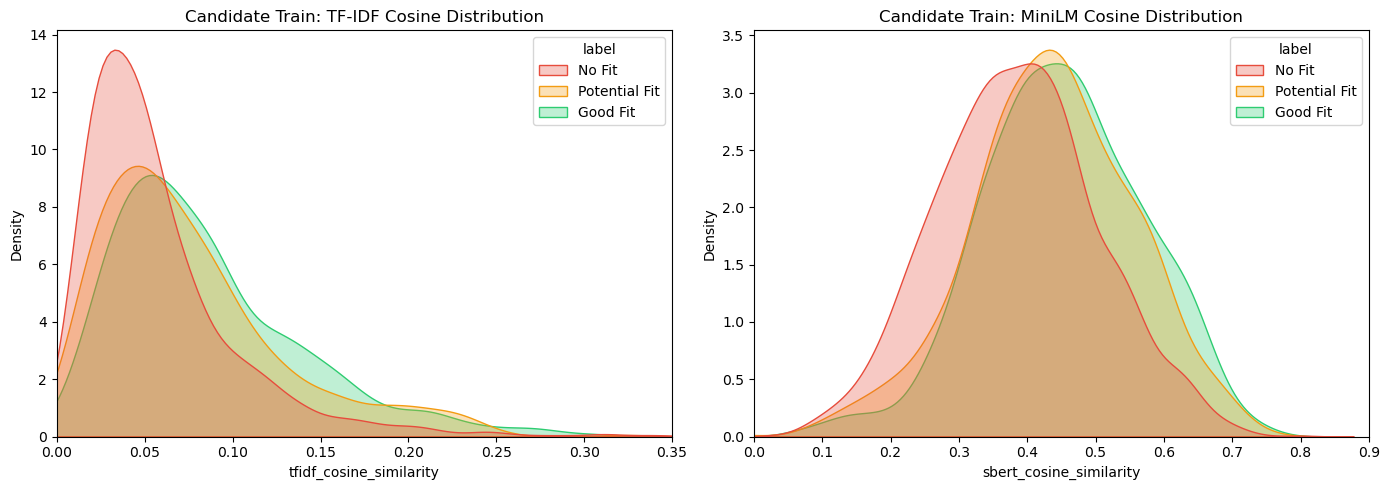

In [8]:
feat_off = pd.read_csv('../data/evaluation/supervised_feature_dataset_official_test.csv')

classes = ['No Fit', 'Potential Fit', 'Good Fit']
sim_rows = []
for sname, sdf in [('candidate_train', feat_train), ('candidate_test', feat_test), ('official_test', feat_off)]:
    for feat in ['tfidf_cosine_similarity', 'sbert_cosine_similarity']:
        for c in classes:
            vals = sdf[sdf['label'] == c][feat]
            q25, q75 = vals.quantile(0.25), vals.quantile(0.75)
            sim_rows.append({
                'Split': sname,
                'Feature': 'TF-IDF' if 'tfidf' in feat else 'MiniLM',
                'Class': c,
                'Mean': f"{vals.mean():.4f}",
                'Median': f"{vals.median():.4f}",
                'Std': f"{vals.std():.4f}",
                'IQR': f"[{q25:.3f}, {q75:.3f}]"
            })

print(pd.DataFrame(sim_rows).to_string(index=False))

# Plot distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = {'No Fit': '#e74c3c', 'Potential Fit': '#f39c12', 'Good Fit': '#2ecc71'}
sns.kdeplot(data=feat_train, x='tfidf_cosine_similarity', hue='label', palette=palette, common_norm=False, fill=True, ax=axes[0], alpha=0.3)
axes[0].set_title('Candidate Train: TF-IDF Cosine Distribution')
axes[0].set_xlim(0, 0.35)

sns.kdeplot(data=feat_train, x='sbert_cosine_similarity', hue='label', palette=palette, common_norm=False, fill=True, ax=axes[1], alpha=0.3)
axes[1].set_title('Candidate Train: MiniLM Cosine Distribution')
axes[1].set_xlim(0, 0.9)
plt.tight_layout()
plt.show()


## 9. Pairwise Class Separability (Cohen's d, Overlap %, ROC-AUC)
We examine the statistical separability of adjacent and extreme class pairs.


In [9]:
def calc_cohens_d(x, y):
    dof = len(x) + len(y) - 2
    p_std = np.sqrt(((len(x)-1)*np.var(x, ddof=1) + (len(y)-1)*np.var(y, ddof=1)) / dof)
    return (np.mean(y) - np.mean(x)) / p_std if p_std > 0 else 0.0

def calc_overlap(x, y, bins=100):
    min_v, max_v = min(x.min(), y.min()), max(x.max(), y.max())
    h1, edges = np.histogram(x, bins=bins, range=(min_v, max_v), density=True)
    h2, _ = np.histogram(y, bins=bins, range=(min_v, max_v), density=True)
    bw = edges[1] - edges[0]
    return min(1.0, float(np.sum(np.minimum(h1, h2)) * bw))

pairs = [('No Fit', 'Potential Fit'), ('Potential Fit', 'Good Fit'), ('No Fit', 'Good Fit')]
sep_rows = []

for sname, sdf in [('candidate_train', feat_train), ('candidate_test', feat_test), ('official_test', feat_off)]:
    for feat in ['tfidf_cosine_similarity', 'sbert_cosine_similarity']:
        for c1, c2 in pairs:
            x1 = sdf[sdf['label'] == c1][feat].values
            x2 = sdf[sdf['label'] == c2][feat].values
            d = calc_cohens_d(x1, x2)
            ovl = calc_overlap(x1, x2)
            y_sub = np.concatenate([np.zeros(len(x1)), np.ones(len(x2))])
            x_sub = np.concatenate([x1, x2])
            auc = roc_auc_score(y_sub, x_sub)
            sep_rows.append({
                'Split': sname,
                'Feature': 'TF-IDF' if 'tfidf' in feat else 'MiniLM',
                'Class Pair': f"{c1} vs {c2}",
                'Cohens d': f"{d:+.4f}",
                'Overlap (%)': f"{ovl*100:.1f}%",
                'ROC-AUC': f"{auc:.4f}"
            })

print(pd.DataFrame(sep_rows).to_string(index=False))


          Split Feature                Class Pair Cohens d Overlap (%) ROC-AUC
candidate_train  TF-IDF   No Fit vs Potential Fit  +0.3836       79.7%  0.6171
candidate_train  TF-IDF Potential Fit vs Good Fit  +0.1744       82.9%  0.5600
candidate_train  TF-IDF        No Fit vs Good Fit  +0.5739       71.1%  0.6800
candidate_train  MiniLM   No Fit vs Potential Fit  +0.4287       79.6%  0.6249
candidate_train  MiniLM Potential Fit vs Good Fit  +0.1329       84.6%  0.5351
candidate_train  MiniLM        No Fit vs Good Fit  +0.5655       74.0%  0.6583
 candidate_test  TF-IDF   No Fit vs Potential Fit  +0.4060       73.9%  0.6236
 candidate_test  TF-IDF Potential Fit vs Good Fit  +0.3860       68.7%  0.6096
 candidate_test  TF-IDF        No Fit vs Good Fit  +0.8134       61.2%  0.7234
 candidate_test  MiniLM   No Fit vs Potential Fit  +0.4425       71.3%  0.6175
 candidate_test  MiniLM Potential Fit vs Good Fit  +0.0529       73.9%  0.5188
 candidate_test  MiniLM        No Fit vs Good Fit  +

## 10. Label Noise & Structural Ambiguity Indicators
We quantify instances of conflicting supervision and extreme similarity anomalies.


In [10]:
# High similarity pairs labeled No Fit
high_tfidf_no = (feat_train['tfidf_cosine_similarity'] > 0.15) & (feat_train['label'] == 'No Fit')
high_sbert_no = (feat_train['sbert_cosine_similarity'] > 0.60) & (feat_train['label'] == 'No Fit')
very_high_sbert_no = (feat_train['sbert_cosine_similarity'] > 0.70) & (feat_train['label'] == 'No Fit')

# Low similarity pairs labeled Good Fit
low_tfidf_good = (feat_train['tfidf_cosine_similarity'] < 0.03) & (feat_train['label'] == 'Good Fit')
low_sbert_good = (feat_train['sbert_cosine_similarity'] < 0.30) & (feat_train['label'] == 'Good Fit')

# Leave-one-out 1-NN self-agreement in candidate_train
nn_sbert_tr = NearestNeighbors(n_neighbors=2, metric='euclidean').fit(X_tr_sbert)
_, idxs_sbert = nn_sbert_tr.kneighbors(X_tr_sbert)
sbert_1nn_agree = (feat_train['label'].values == feat_train['label'].values[idxs_sbert[:, 1]]).mean() * 100

nn_18_tr = NearestNeighbors(n_neighbors=2, metric='euclidean').fit(X_tr_18)
_, idxs_18 = nn_18_tr.kneighbors(X_tr_18)
feat18_1nn_agree = (feat_train['label'].values == feat_train['label'].values[idxs_18[:, 1]]).mean() * 100

print(f"High TF-IDF similarity (>0.15) labeled 'No Fit': {high_tfidf_no.sum()} pairs")
print(f"High MiniLM similarity (>0.60) labeled 'No Fit': {high_sbert_no.sum()} pairs")
print(f"Very High MiniLM similarity (>0.70) labeled 'No Fit': {very_high_sbert_no.sum()} pairs")
print(f"Low TF-IDF similarity (<0.03) labeled 'Good Fit': {low_tfidf_good.sum()} pairs")
print(f"Low MiniLM similarity (<0.30) labeled 'Good Fit': {low_sbert_good.sum()} pairs")
print(f"Leave-one-out 1-NN Agreement in 1D MiniLM space: {sbert_1nn_agree:.2f}%")
print(f"Leave-one-out 1-NN Agreement in 18-Feature Model F space: {feat18_1nn_agree:.2f}%")


High TF-IDF similarity (>0.15) labeled 'No Fit': 86 pairs
High MiniLM similarity (>0.60) labeled 'No Fit': 80 pairs
Very High MiniLM similarity (>0.70) labeled 'No Fit': 6 pairs
Low TF-IDF similarity (<0.03) labeled 'Good Fit': 96 pairs
Low MiniLM similarity (<0.30) labeled 'Good Fit': 80 pairs
Leave-one-out 1-NN Agreement in 1D MiniLM space: 41.06%
Leave-one-out 1-NN Agreement in 18-Feature Model F space: 50.96%


## 11. Empirical Performance Ceiling Assessment

Based on the quantitative audit:
- **Selected Assessment**: **D. Dataset structure makes high accuracy unrealistic** (with **C. Low evidence for >60%**).
- **Justification**:
  1. **Indistinguishable Boundary**: In MiniLM semantic space, the ROC-AUC for `Potential Fit` vs `Good Fit` is **0.5351** on candidate train and **0.5188** on candidate test, dropping to **0.4441** on official test. Over 84% of their distribution volume overlaps.
  2. **Contradictory Duplicate Supervision**: 85.7% (6/7) of identical `(resume_text, job_description_text)` pairs carry contradictory labels.
  3. **Low Neighborhood Predictability**: Leave-one-out 1-NN agreement in training is only **41.06%** for MiniLM and **50.96%** across all 18 features (virtually identical to the 51.04% trivial majority baseline).
  4. **Plateau Across Diverse Model Families**: Across linear models (Model A: 0.4735/0.4220), heavy transformers (Cross-Encoder: 0.4357, MPNet: 0.4079), gradient-boosted trees (Model F: 0.4712/0.4360), and blended ensembles (0.5275/0.4232), Macro F1 consistently plateaus near 0.44–0.54.


## 12. Conclusions & Next Modeling Direction

### Key Findings:
1. **70–80% 3-class accuracy is NOT achievable** on this dataset in its present formulation.
2. The bottleneck is **label boundary ambiguity between Potential Fit and Good Fit**, not representation capacity.
3. Simply introducing a larger or heavier neural network will not resolve label contradictions where identical or near-identical text pairs are assigned conflicting target classes.

### Recommended Next Modeling Directions:
1. **Relative Ranking / Learning-to-Rank (LTR)**: In real recruitment workflows, hiring managers rank candidate resumes for a given job rather than assigning absolute 3-class discrete buckets. Re-framing the problem to pairwise candidate ranking bypasses the ambiguous absolute boundary between `Potential Fit` and `Good Fit`.
2. **Boundary Cleaning & Probabilistic Guardrails**: If 3-class classification is retained, confidence calibration (e.g., Model F + Temperature Scaling $T=1.4173$) remains essential to communicate uncertainty honestly to human recruiters.
